In [194]:
# importing libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

from xgboost import XGBRegressor

In [195]:
waves = pd.read_csv('Waves_2023.txt', sep=r'\s+')

In [196]:
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [197]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [198]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]
waves = waves[waves['WTMP']<99]

In [199]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)

In [200]:
wavesML

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5
...,...,...,...,...,...
17280,2.01,14.29,11.19,270,16.7
17281,1.75,15.38,10.37,267,16.7
17282,1.79,13.33,10.50,268,16.8
17283,1.66,14.29,10.32,271,16.8


In [201]:
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy()
df_y = wavesML['WVHT'].to_numpy()

In [202]:
# 80% training, 10% validation, and 10% testing
X_train, X_other, y_train, y_other = train_test_split(df_X, df_y, test_size=0.20)
X_val, X_test, y_val, y_test = train_test_split(X_other, y_other, test_size=0.50)

In [203]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (13820, 4)
Validation: (1728, 4)
Test: (1728, 4)


In [204]:
regLinear = LinearRegression()
regLinear.fit(X_train, y_train)

LinearRegression()

In [205]:
regBoosting = XGBRegressor(n_estimators=25,objective="reg:squarederror",eval_metric="rmse",random_state=42)
regBoosting.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=25,
             n_jobs=None, num_parallel_tree=None, ...)

In [206]:
linear_train_mse = mean_squared_error(y_train,regLinear.predict(X_train))
linear_val_mse = mean_squared_error(y_val,regLinear.predict(X_val))
linear_test_mse = mean_squared_error(y_test,regLinear.predict(X_test))

In [207]:
boosting_train_mse = mean_squared_error(y_train,regBoosting.predict(X_train))
boosting_val_mse = mean_squared_error(y_val,regBoosting.predict(X_val))
boosting_test_mse = mean_squared_error(y_test,regBoosting.predict(X_test))

In [208]:
model_results = pd.DataFrame({
  "Model": ["Linear Regression","XGBoost"],
  "Training MSE": [linear_train_mse,boosting_train_mse],
  "Validation MSE":[linear_val_mse,boosting_val_mse],
  "Test MSE": [linear_test_mse,boosting_test_mse]})
model_results.round(6)

,Model,Training MSE,Validation MSE,Test MSE
0,Linear Regression,0.197344,0.209306,0.168533
1,XGBoost,0.071098,0.093766,0.088729


In [209]:
boost2 = XGBRegressor(n_estimators=2,objective="reg:squarederror",eval_metric="rmse",random_state=42)
boost2.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=2,
             n_jobs=None, num_parallel_tree=None, ...)

In [210]:
boost10 = XGBRegressor(n_estimators=10,objective="reg:squarederror",eval_metric="rmse",random_state=42)
boost10.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=10,
             n_jobs=None, num_parallel_tree=None, ...)

In [211]:
boost25 = XGBRegressor(n_estimators=25,objective="reg:squarederror",eval_metric="rmse",random_state=42)
boost25.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=25,
             n_jobs=None, num_parallel_tree=None, ...)

In [212]:
boost50 = XGBRegressor(n_estimators=50,objective="reg:squarederror",eval_metric="rmse",random_state=42)
boost50.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=50,
             n_jobs=None, num_parallel_tree=None, ...)

In [213]:
boost100 = XGBRegressor(n_estimators=100,objective="reg:squarederror",eval_metric="rmse",random_state=42)
boost100.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [214]:
boost250 = XGBRegressor(n_estimators=250,objective="reg:squarederror",eval_metric="rmse",random_state=42)
boost250.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=250,
             n_jobs=None, num_parallel_tree=None, ...)

In [215]:
boost500 = XGBRegressor(n_estimators=500,objective="reg:squarederror",eval_metric="rmse",random_state=42)
boost500.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [216]:
boost1000 = XGBRegressor( n_estimators=1000, objective="reg:squarederror", eval_metric="rmse", random_state=42)
boost1000.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=None, num_parallel_tree=None, ...)

In [217]:
number_of_iterations = [2, 10, 25, 50, 100, 250, 500, 1000]

training_mse = [
    mean_squared_error(y_train, boost2.predict(X_train)),
    mean_squared_error(y_train, boost10.predict(X_train)),
    mean_squared_error(y_train, boost25.predict(X_train)),
    mean_squared_error(y_train, boost50.predict(X_train)),
    mean_squared_error(y_train, boost100.predict(X_train)),
    mean_squared_error(y_train, boost250.predict(X_train)),
    mean_squared_error(y_train, boost500.predict(X_train)),
    mean_squared_error(y_train, boost1000.predict(X_train))]

In [218]:
validation_mse = [
    mean_squared_error(y_val, boost2.predict(X_val)),
    mean_squared_error(y_val, boost10.predict(X_val)),
    mean_squared_error(y_val, boost25.predict(X_val)),
    mean_squared_error(y_val, boost50.predict(X_val)),
    mean_squared_error(y_val, boost100.predict(X_val)),
    mean_squared_error(y_val, boost250.predict(X_val)),
    mean_squared_error(y_val, boost500.predict(X_val)),
    mean_squared_error(y_val, boost1000.predict(X_val))
]

In [219]:
boosting_results = pd.DataFrame({
    'Boosting Iterations': number_of_iterations,
    'Training MSE (m²)': training_mse,
    'Validation MSE (m²)': validation_mse})
boosting_results.round(6)

,Boosting Iterations,Training MSE (m²),Validation MSE (m²)
0,2,0.156577,0.172882
1,10,0.090908,0.109078
2,25,0.071098,0.093766
3,50,0.056357,0.087307
4,100,0.042243,0.085415
5,250,0.023471,0.084205
6,500,0.011294,0.089457
7,1000,0.003776,0.093475


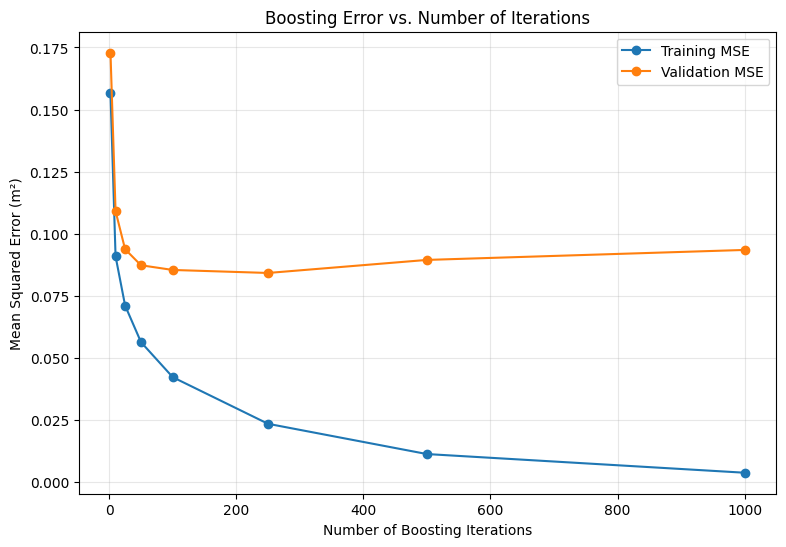

In [220]:
plt.figure(figsize=(9, 6))
plt.plot(number_of_iterations,training_mse,marker='o',label='Training MSE')
plt.plot(number_of_iterations,validation_mse,marker='o',label='Validation MSE')
plt.xlabel('Number of Boosting Iterations')
plt.ylabel('Mean Squared Error (m²)')
plt.title('Boosting Error vs. Number of Iterations')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [221]:
print('1,000-iteration training MSE:',training_mse[7])
print('1,000-iteration validation MSE:',validation_mse[7])

1,000-iteration training MSE: 0.003775662934268578
1,000-iteration validation MSE: 0.0934751147975935


In [222]:
boostEarly = XGBRegressor(n_estimators=1000,objective="reg:squarederror",eval_metric="rmse",early_stopping_rounds=10,random_state=42)
boostEarly.fit(X_train,y_train,eval_set=[(X_val, y_val)],verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=10,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=None, num_parallel_tree=None, ...)

In [223]:
optimal_iterations = boostEarly.best_iteration + 1
print('Optimal number of boosting iterations:',boostEarly.best_iteration+1)

Optimal number of boosting iterations: 63


In [224]:
early_train_mse = mean_squared_error(y_train,boostEarly.predict(X_train))
early_val_mse = mean_squared_error(y_val,boostEarly.predict(X_val))
early_test_mse = mean_squared_error(y_test,boostEarly.predict(X_test))

In [225]:
early_results = pd.DataFrame({
    "Model": ["XGBoost with Early Stopping"],
    "Optimal Iterations": [optimal_iterations],
    "Training MSE": [early_train_mse],
    "Validation MSE": [early_val_mse],
    "Test MSE": [early_test_mse]})
early_results.round(6)

,Model,Optimal Iterations,Training MSE,Validation MSE,Test MSE
0,XGBoost with Early Stopping,63,0.052013,0.085957,0.088223
